<a href="https://colab.research.google.com/github/BradKruithof/Brad_INFO4670_Fall2026/blob/main/Copy_of_Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [8]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/car_purchase_data.csv')

# Preview the first few rows
display(df.head())

,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


### Step 2: Split features and target

In [9]:
# Extract features (Age, Salary) and target (Purchased)
X = df[['Age', 'Salary']].values
y = df['Purchased'].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (400, 2)
y shape: (400,)


### Step 3: Train/Test Split

In [10]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (320, 2)
X_test shape: (80, 2)


### Step 4: Feature Scaling

In [11]:
from sklearn.preprocessing import StandardScaler

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit on training data and transform both training and testing sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("First 5 rows of scaled training features:\n", X_train_scaled[:5])

First 5 rows of scaled training features:
 [[-1.06675246 -0.38634438]
 [ 0.79753468 -1.22993871]
 [ 0.11069205  1.853544  ]
 [ 0.60129393 -0.90995465]
 [ 1.87685881 -1.28811763]]


### Step 5: Train Logistic Regression Model

In [12]:
from sklearn.linear_model import LogisticRegression

# Initialize and train the Logistic Regression model
classifier = LogisticRegression(random_state=42)
classifier.fit(X_train_scaled, y_train)

print("Model training completed.")

Model training completed.


### Step 6: Predict and Evaluate

In [13]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Predict the test set results
y_pred = classifier.predict(X_test_scaled)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy Score: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:")
print(cm)
print("\nClassification Report:")
print(report)

Accuracy Score: 86.25%

Confusion Matrix:
[[50  2]
 [ 9 19]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.96      0.90        52
           1       0.90      0.68      0.78        28

    accuracy                           0.86        80
   macro avg       0.88      0.82      0.84        80
weighted avg       0.87      0.86      0.86        80



### Step 7: Visualization of Decision Regions

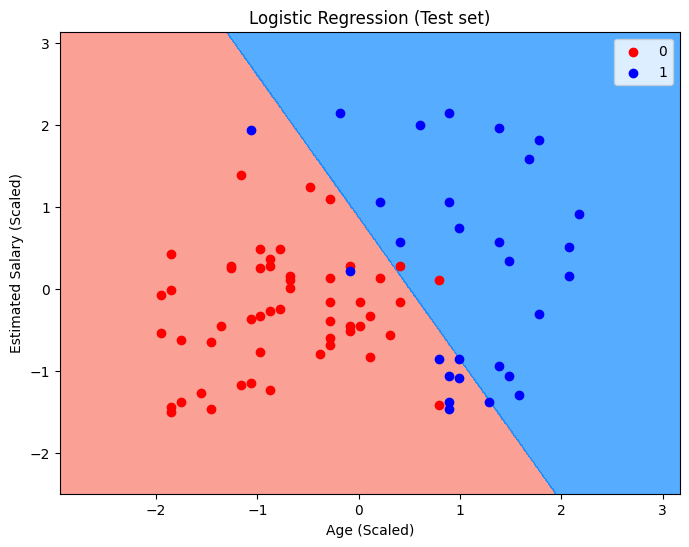

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Create a mesh grid for visualization
X_set, y_set = X_test_scaled, y_test
X1, X2 = np.meshgrid(np.arange(start=X_set[:, 0].min() - 1, stop=X_set[:, 0].max() + 1, step=0.01),
                     np.arange(start=X_set[:, 1].min() - 1, stop=X_set[:, 1].max() + 1, step=0.01))

plt.figure(figsize=(8, 6))
plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha=0.75, cmap=ListedColormap(('salmon', 'dodgerblue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                color=ListedColormap(('red', 'blue'))(i), label=str(j))

plt.title('Logistic Regression (Test set)')
plt.xlabel('Age (Scaled)')
plt.ylabel('Estimated Salary (Scaled)')
plt.legend()
plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


### Answers to Reflection Questions

1. **Logistic regression outputs probabilities — why can it still be used for classification?**  
   Logistic regression applies the Sigmoid function to output a probability value between 0 and 1. We can map this continuous probability to discrete classes (0 or 1) by choosing a threshold (typically 0.5). If the predicted probability is $\ge 0.5$, we classify it as 1 (Purchase); otherwise, we classify it as 0.

2. **Based on your model, which customers are more likely to purchase a car?**  
   Customers who are older and have higher incomes  are significantly more likely to purchase a car, as shown by the positive weights/coefficients assigned to these variables.

3. **What factors might cause low accuracy in this task?**  
   Non-linear relationships, since logistic regression is a linear classifier, if the boundary is highly non-linear, it will misclassify.  
   Also, Noise/Outliers in the data. Individuals with high salaries who didn't buy, or young individuals with low salaries who did buy.  
  

4. **Propose additional features or preprocessing steps that could improve accuracy.**  
   Include the `Gender` feature using One-Hot encoding, Create interaction features (e.g., `Age * Salary`), and lastly try non-linear classifiers.